# Lab 1: Neural Models

**Name:** Mehta Prem Kalpesh

**ID:** 2024ADPS0851G

**Scenario:** Two redundant binary sensors; warn exactly when they disagree (XOR).

## Task 1: Understand the problem before coding

### 1.1 Problem specification
Write the input space $\mathcal{X}$, output space $\mathcal{Y}$, and all four labelled examples.

**Answer:**  
- Input space: $\mathcal{X} = \{0,1\}^2 = \{(0,0),(0,1),(1,0),(1,1)\}$  
- Output space: $\mathcal{Y} = \{0,1\}$ (1 = disagreement warning)  
- Labelled examples: $(0,0)\to 0$, $(0,1)\to 1$, $(1,0)\to 1$, $(1,1)\to 0$

### 1.2 Sketch of the four points


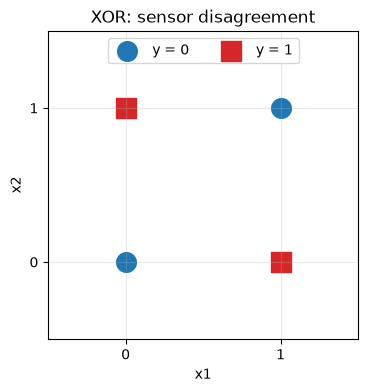

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([0, 1, 1, 0], dtype=float)

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", s=200, label="y = 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", s=200, marker="s", label="y = 1")
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.grid(True, alpha=0.3)
ax.legend(loc="upper center", ncol=2)
ax.set_title("XOR: sensor disagreement")
plt.show()

### 1.3 Why can one straight line not separate the classes?

**Answer:**  
The two classes sit on opposite diagonals of the unit square: the class-1 points $(0,1),(1,0)$ lie on one diagonal and the class-0 points $(0,0),(1,1)$ on the other. A line $w_1x_1+w_2x_2+b=0$ would have to keep each diagonal's two points on the same side, but the segments joining each pair cross at $(0.5,0.5)$, so no such line exists.

**Algebraic proof.** A separating line needs  
$b<0$ (for $(0,0)$), $w_1+w_2+b<0$ (for $(1,1)$), $w_1+b>0$ (for $(1,0)$), $w_2+b>0$ (for $(0,1)$).  
Adding the last two gives $w_1+w_2+2b>0$. Adding the first two gives $w_1+w_2+2b<0$. Contradiction, so no $(w_1,w_2,b)$ works.

### 1.4 Prediction: single affine layer + sigmoid
What will happen if we train only $\sigma(w_1 x_1 + w_2 x_2 + b)$ on these four points?

**Prediction:**  
A single affine layer plus sigmoid is a linear classifier, so it can get at most 3 of the 4 points right. Binary cross-entropy is convex in $(w,b)$, and its minimum is at $w_1=w_2=b=0$: the gradient there is $\sum_i (p_i-y_i)x_i = 0$ by symmetry. So I predict the model outputs $p\approx 0.5$ for every input, the loss plateaus near $\ln 2\approx 0.693$, and accuracy is only about 2/4 (which points count as correct depends on how $p=0.5$ is thresholded).

### Task 1 Think About It
A model can have many parameters and still have the wrong kind of representation. What scientific claim about representation does XOR let us test with only four data points?

**Answer:**  
XOR lets us test that the kind of representation matters more than the number of parameters. A hidden layer with a nonlinear activation can learn a new representation of the inputs in which the classes are linearly separable, and the output layer then separates them with one line. With four points we can check this directly: the linear model fails and the 2-2-1 nonlinear model succeeds.

## Task 2: Design the intelligent agent

**Model specification**
- Architecture: 2 inputs $\to$ 2 hidden units $\to$ 1 output
- Hidden activation: sigmoid 
- Output: sigmoid, giving $p=P(y=1\mid x)$
- Loss: binary cross-entropy, $L=-\frac14\sum_i\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]$
- Optimiser: gradient-based (full-batch)

### 2.1 Why is the hidden nonlinearity scientifically necessary?
Without it the network is $W_2(W_1x+b_1)+b_2 = (W_2W_1)x + (W_2b_1+b_2) = W_{\text{eff}}\,x + b_{\text{eff}}$, which is a single affine layer in disguise. Adding affine-only depth therefore adds no representational power, and XOR (not linearly separable) stays impossible. The ingredient that helps is the nonlinearity, not the depth.

### 2.2 Why is sigmoid + binary cross-entropy a sensible pairing?
- The target is a single yes/no answer, so we need one number in $(0,1)$. The sigmoid gives $p=P(y=1)$, and $P(y=0)=1-p$ follows automatically.
- BCE is the negative log-likelihood of a Bernoulli model with parameter $p$, so minimising it is maximum-likelihood estimation for this output.
- The pairing has a clean gradient: $\partial L/\partial z = p-y$ for the logit $z$. The sigmoid's derivative cancels, so a confidently wrong output does not get a vanishing gradient.

### 2.3 Evidence of successful learning
1. **Final loss** is close to 0 (for example below 0.05), well below the $\ln 2\approx0.693$ plateau of the linear model.
2. **All four thresholded predictions** match the labels, with probabilities clearly away from 0.5.
3. **Gradient check:** the first-layer gradient is nonzero during training, and the loss decreases steadily (no NaN, no oscillation).
4. **Repeated runs:** across several random seeds, report how often training succeeds. A 2-2-1 network can get stuck, so one lucky run is not enough evidence.

### Task 2 Think About It
The hidden units are not given target values. If the network learns XOR, what has determined what each hidden unit should compute? Relate your answer to the role of backpropagation.

**Answer:**  
Each hidden unit computes $h_j=\sigma(w_j^\top x+b_j)$, and what it ends up computing is decided by the output-layer error. Backpropagation applies the chain rule to the loss, so each hidden weight receives a gradient $\partial L/\partial w_j$ that measures how changing that weight would change the final loss, passed back through the output weights. The optimiser then moves the weights downhill on that gradient. Over training, each hidden unit is pushed towards whatever feature makes the output's job easier.

## Task 3: Use an LLM to generate a first implementation

### 3.1 Exact prompt used
> I want to build a small autonomous device with two redundant binary sensors, x1 and x2. The device should raise a sensor-disagreement warning exactly when one sensor is active and the other is inactive. The required decision rule is therefore XOR:
> (0,0) -> 0
> (0,1) -> 1
> (1,0) -> 1
> (1,1) -> 0
>
> We will create a 2 input -> 2 hidden -> 1 output neural model with tanh activation function. It should have logits with BCEWithLogitsLoss in PyTorch with random weights initialisation. Use full batch training for 4 thousand steps. For the Optimizer, choose Adam with lr = 1e-3.
>
> Generate minimal PyTorch code for the following model and dataset. Do not change the architecture or task. After training, report the final loss, all four probabilities, thresholded labels, first-layer weight-gradient tensor. Set a random seed for reproducibility and explain each test in one sentence. Report the initial and Final loss. 

### 3.2 Generated code

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

# Set random seed for reproducibility
torch.manual_seed(42)

# XOR Dataset
X = torch.tensor([[0.0, 0.0],
                  [0.0, 1.0],
                  [1.0, 0.0],
                  [1.0, 1.0]])
y = torch.tensor([[0.0],
                  [1.0],
                  [1.0],
                  [0.0]])

# Define model architecture (2 inputs -> 2 hidden -> 1 output)
model = nn.Sequential(
    nn.Linear(2, 2),
    nn.Tanh(),
    nn.Linear(2, 1)
)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Calculate initial loss before training
initial_logits = model(X)
initial_loss = criterion(initial_logits, y).item()

# Full batch training for 4,000 steps
for step in range(4000):
    optimizer.zero_grad() 
    logits = model(X) #forward pass
    loss = criterion(logits, y) #scalar loss
    loss.backward() #auto-diff
    optimizer.step() #optimiser changes parameters

# Retrieve final metrics
final_loss = loss.item()
final_logits = model(X)
probs = torch.sigmoid(final_logits)
thresholded_labels = (probs > 0.5).int()
first_layer_grad = model[0].weight.grad

# Output formatting
print(f"Initial Loss: {initial_loss:.4f}")
print(f"Final Loss: {final_loss:.4f}")
print(f"Probabilities:\n{probs.detach().numpy()}")
print(f"Thresholded Labels:\n{thresholded_labels.detach().numpy()}")
print(f"First-Layer Weight Gradient Tensor:\n{first_layer_grad.numpy()}")

Initial Loss: 0.7563
Final Loss: 0.0447
Probabilities:
[[0.03016567]
 [0.93219453]
 [0.94509006]
 [0.02112125]]
Thresholded Labels:
[[0]
 [1]
 [1]
 [0]]
First-Layer Weight Gradient Tensor:
[[ 0.00626174 -0.00218701]
 [ 0.00275942 -0.0046804 ]]


### 3.3 Code inspection (by hand, before trusting the output)
- **Forward pass:** `logits = model(X)`, a raw `Linear` output, with no sigmoid in the model.
- **Scalar loss:** `loss = criterion(logits, y)`, BCE with the sigmoid applied inside.
- **Reverse-mode autodiff:** `loss.backward()` fills `.grad` on every parameter.
- **Optimiser step:** `optimizer.step()` (Adam) changes the parameters using those gradients.
- **Subtle issue:** `first_layer_grad` and `final_loss` come from the last `backward()`, which ran *before* the final `optimizer.step()`. They belong to the parameters one step earlier than those used for the printed probabilities. Here the difference is negligible, but a cleaner version re-computes loss and gradient once after training.

### 3.4 Results (seed 42, CPU)
Initial loss 0.7563, final loss 0.0447, probabilities about [0.030, 0.932, 0.945, 0.021], labels [0, 1, 1, 0], first-layer gradient about [[0.0063, -0.0022], [0.0028, -0.0047]]. The loss was still about 0.687 (the linear plateau) at step 500 and only fell clearly afterwards.

### Task 3 Think About It
Which parts of the lab can be verified by reading the code, and which only by running it?

**Answer:**  
- **Verifiable by reading the code alone:** syntax, design (architecture, loss and output pairing, optimiser choice) and the order of steps (zero gradients, forward, loss, backward, step).
- **Verifiable only by running it:** convergence, the actual loss values, the gradients, and whether learning succeeded or failed.

## Task 4: Test the model

### 4A. Seed robustness
**Prediction:** all 10 seeds (0 to 9) will reach all four labels correct, because the model learns from whatever random initialisation it is given.

**Result:** the prediction was wrong. With Adam at lr=1e-3 and 4000 steps, only 3/10 seeds succeeded (0, 3, 4). With lr=1e-2, only 4/10 succeeded (0, 2, 3, 4).

**Interpretation:** a 2-2-1 network has almost no spare capacity, so some initialisations end up in a poor configuration that gradient descent cannot escape. The failures are not just slow runs: at lr=1e-2 five seeds stop at a loss of exactly 0.3467 (two inputs stuck at p=0.5, the other two correct) and one at 0.4774 (three inputs at p=0.667). A single successful seed is therefore not evidence that the method works.

In [3]:
def run(seed, steps=4000, lr=1e-3):
    torch.manual_seed(seed)
    m = nn.Sequential(nn.Linear(2, 2), nn.Tanh(), nn.Linear(2, 1))
    c = nn.BCEWithLogitsLoss()
    o = optim.Adam(m.parameters(), lr=lr)
    for _ in range(steps):
        o.zero_grad()
        l = c(m(X), y)
        l.backward()
        o.step()
    with torch.no_grad():
        p = torch.sigmoid(m(X)).squeeze()
        l = c(m(X), y).item()
    return l, p, int(((p > 0.5).float() == y.squeeze()).all())

for lr in (1e-3, 1e-2):
    print("lr", lr)
    ok = 0
    for s in range(10):
        l, p, a = run(s, lr=lr)
        ok += a
        print(s, round(l, 4), p.numpy().round(3), "OK" if a else "FAIL")
    print("success", ok, "/10")

lr 0.001
0 0.0372 [0.03  0.959 0.949 0.023] OK
1 0.3592 [0.013 0.496 0.985 0.507] FAIL
2 0.4843 [0.337 0.991 0.33  0.336] FAIL
3 0.052 [0.049 0.932 0.949 0.035] OK
4 0.0564 [0.042 0.923 0.938 0.039] OK
5 0.3586 [0.014 0.986 0.495 0.505] FAIL
6 0.3562 [0.009 0.99  0.496 0.505] FAIL
7 0.4833 [0.008 0.665 0.663 0.67 ] FAIL
8 0.3576 [0.011 0.993 0.491 0.504] FAIL
9 0.3588 [0.01  0.99  0.493 0.507] FAIL
success 3 /10
lr 0.01
0 0.0005 [0.    0.999 0.999 0.   ] OK
1 0.3467 [0.  0.5 1.  0.5] FAIL
2 0.0003 [0.    1.    0.999 0.   ] OK
3 0.0006 [0.    0.999 0.999 0.   ] OK
4 0.0007 [0.    0.999 0.999 0.   ] OK
5 0.3467 [0.  1.  0.5 0.5] FAIL
6 0.3467 [0.  1.  0.5 0.5] FAIL
7 0.4774 [0.    0.667 0.667 0.667] FAIL
8 0.3467 [0.  1.  0.5 0.5] FAIL
9 0.3467 [0.  1.  0.5 0.5] FAIL
success 4 /10


### 4B. Backpropagation check
After `loss.backward()`, `model[0].weight.grad` holds $\partial L/\partial W^{(1)}$: the sensitivity of the scalar loss to each first-layer weight.

- **Shape:** $2\times2$, the same as the weight matrix. Row $j$ belongs to hidden unit $j$, and column $i$ to input $x_i$. Entry $(j,i)$ is $\partial L/\partial W^{(1)}_{ji}$.
- **Sign:** a positive entry means increasing that weight would increase the loss, so gradient descent decreases it. A negative entry means the weight is increased.
- **Mean loss:** `BCEWithLogitsLoss` averages over the four examples, $L=\frac14\sum_{n}L_n$. Differentiation is linear, so $\partial L/\partial W=\frac14\sum_n \partial L_n/\partial W$: the gradient is the average of the example-wise gradients.
- **Size of the gradient:** a small gradient does *not* by itself mean the model is near a good minimum. It only means the loss surface is flat there. Flat regions include true minima, plateaus and stuck configurations.

Gradient norms from the experiments (first-layer weight gradient):

| Run | Loss | Gradient norm |
|---|---|---|
| seed 42, lr 1e-3, step 0 | 0.7563 | 0.0287 |
| seed 42, step 500 (still on plateau) | 0.6866 | 0.0238 |
| seed 42, step 4000 (learned) | 0.0447 | 0.0086 |
| seed 1, lr 1e-2, step 4000 (**stuck**) | 0.3467 | 0.00011 |
| seed 0, lr 1e-2, step 4000 (learned) | 0.0005 | 0.00006 |

The stuck run and the successful run have gradient norms of the same tiny size, so the gradient alone cannot tell them apart. You must also look at the loss and the predictions.

In [4]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(2, 2), nn.Tanh(), nn.Linear(2, 1))
crit = nn.BCEWithLogitsLoss()

# Gradient of the mean loss over all four examples
model.zero_grad()
crit(model(X), y).backward()
g_mean = model[0].weight.grad.clone()

# Gradient of each example's loss separately
per = []
for i in range(4):
    model.zero_grad()
    crit(model(X[i:i+1]), y[i:i+1]).backward()
    per.append(model[0].weight.grad.clone())
per = torch.stack(per)

print("mean-loss grad:\n", g_mean)
print("average of per-example grads:\n", per.mean(0))
print("match:", torch.allclose(g_mean, per.mean(0), atol=1e-7))

mean-loss grad:
 tensor([[ 0.0040, -0.0014],
        [ 0.0068,  0.0275]])
average of per-example grads:
 tensor([[ 0.0040, -0.0014],
        [ 0.0068,  0.0275]])
match: True


### 4C. Symmetry experiment
**Prediction:** the two hidden-weight rows stay identical and the network does not learn XOR; random initialisation is needed so the hidden units become different.

Three initialisations were trained with the same setup as before (Adam, lr=1e-3, 4000 steps), watching the two rows of `model[0].weight`:

| Init | Rows identical? | Final loss | Probabilities |
|---|---|---|---|
| A: all weights and biases zero (lab's version) | yes, and nothing moves at all | 0.6931 | 0.5, 0.5, 0.5, 0.5 |
| B: first layer zero, output layer random | **no** (rows end up with opposite signs) | 0.6931 | 0.5, 0.5, 0.5, 0.5 |
| C: every weight 0.5, biases 0 | yes, at every step | 0.4861 | 0.017, 0.666, 0.666, 0.671 |

**Interpretation**
- **A:** with the output weights zero, the error cannot flow back into the first layer ($\partial L/\partial W^{(1)}$ is multiplied by $W^{(2)}=0$). With the hidden activations $\tanh(0)=0$, the output weights get no gradient either. Only the output bias gets one, and for balanced labels its best value is 0, so nothing changes. The rows stay identical because they never move.
- **C:** this is the pure symmetry case. Two identical hidden units compute the same output and receive the same gradient, so every update changes them identically and they stay identical forever. The pair acts as one hidden unit, which is not enough for XOR, so the loss stalls at 0.486 with three outputs at about 0.67.
- **B:** the rows *do* separate, because different output weights send different gradients to the two units. It still fails. The printed rows show each unit giving both inputs the same weight, so each unit sees only $x_1+x_2$, and the data's $x_1\leftrightarrow x_2$ symmetry is never broken. (I read this off the printed weights and did not prove it.) Breaking the symmetry between *units* is not enough; the starting point must also differ in a way that separates the inputs.
- **Conclusion:** random initialisation is not a convenience. It is what makes the hidden units different, so that they receive different gradients and can learn different features.

In [5]:
def sym_exp(name, init, steps=4000, lr=1e-3):
    torch.manual_seed(42)
    m = nn.Sequential(nn.Linear(2, 2), nn.Tanh(), nn.Linear(2, 1))
    init(m)
    c = nn.BCEWithLogitsLoss()
    o = optim.Adam(m.parameters(), lr=lr)
    print("==", name)
    for s in range(steps + 1):
        o.zero_grad()
        l = c(m(X), y)
        l.backward()
        if s in (0, 1, 10, 100, 1000, 4000):
            W = m[0].weight.detach()
            print(f"step {s:4d} loss {l.item():.4f} rows {W[0].numpy().round(4)} {W[1].numpy().round(4)}"
                  f" | |dW1| {m[0].weight.grad.norm().item():.5f}")
        o.step()
    print("probs", torch.sigmoid(m(X)).detach().squeeze().numpy().round(3),
          "| rows identical:", torch.allclose(m[0].weight[0], m[0].weight[1]))

def all_zero(m):
    for p in m.parameters():
        nn.init.zeros_(p)

def first_layer_zero(m):
    nn.init.zeros_(m[0].weight)
    nn.init.zeros_(m[0].bias)

def constant_half(m):
    for l in (m[0], m[2]):
        nn.init.constant_(l.weight, 0.5)
        nn.init.zeros_(l.bias)

sym_exp("A: all zero", all_zero)
sym_exp("B: first layer zero, output random", first_layer_zero)
sym_exp("C: all weights 0.5", constant_half)

== A: all zero
step    0 loss 0.6931 rows [0. 0.] [0. 0.] | |dW1| 0.00000
step    1 loss 0.6931 rows [0. 0.] [0. 0.] | |dW1| 0.00000
step   10 loss 0.6931 rows [0. 0.] [0. 0.] | |dW1| 0.00000
step  100 loss 0.6931 rows [0. 0.] [0. 0.] | |dW1| 0.00000
step 1000 loss 0.6931 rows [0. 0.] [0. 0.] | |dW1| 0.00000
step 4000 loss 0.6931 rows [0. 0.] [0. 0.] | |dW1| 0.00000
probs [0.5 0.5 0.5 0.5] | rows identical: True
== B: first layer zero, output random
step    0 loss 0.7410 rows [0. 0.] [0. 0.] | |dW1| 0.05759
step    1 loss 0.7406 rows [0.001 0.001] [-0.001 -0.001] | |dW1| 0.05733
step   10 loss 0.7372 rows [0.01 0.01] [-0.01 -0.01] | |dW1| 0.05612
step  100 loss 0.7089 rows [0.0921 0.0921] [-0.0913 -0.0913] | |dW1| 0.03094
step 1000 loss 0.6931 rows [0.0007 0.0007] [-0.0013 -0.0013] | |dW1| 0.00012
step 4000 loss 0.6931 rows [0. 0.] [-0. -0.] | |dW1| 0.00000
probs [0.5 0.5 0.5 0.5] | rows identical: False
== C: all weights 0.5
step    0 loss 0.7038 rows [0.5 0.5] [0.5 0.5] | |dW1| 0.004

### 4D. Activation experiment
**Prediction:** tanh has the largest early gradient norm and sigmoid the smallest. To support a general claim, we would need more data points.

Setup: the same network, seed and initial weights for every activation (only the hidden activation changes), Adam, 4000 steps. "Early gradient norm" is $\lVert\partial L/\partial W^{(1)}\rVert$ at step 0.

**Seed 42, lr = 1e-3**

| Activation | Final loss | All 4 correct? | Early gradient norm |
|---|---|---|---|
| sigmoid | 0.2748 | yes | 0.0119 |
| tanh | 0.0447 | yes | 0.0287 |
| ReLU | 0.3506 | no (probs 0.499, 0.992, 0.499, 0.009) | 0.0820 |

**Seeds 0 to 9, lr = 1e-3**

| Activation | Successes | Mean early gradient norm (min to max) | Mean final loss |
|---|---|---|---|
| sigmoid | 5/10 | 0.0062 (0.0009 to 0.0175) | 0.333 |
| tanh | 3/10 | 0.0360 (0.0051 to 0.0731) | 0.290 |
| ReLU | 2/10 | 0.0252 (0.0000 to 0.0930) | 0.549 |

(At lr = 1e-2: sigmoid 6/10, tanh 4/10, ReLU 1/10.)

**Interpretation**
- **The prediction held only partly.** Sigmoid had the smallest early gradient in both views. Tanh had the largest on average over 10 seeds, but on seed 42 ReLU was larger (0.082), and ReLU's range is wide (0.0000 to 0.0930).
- **A bigger early gradient did not mean more success.** Sigmoid had the smallest early gradients yet succeeded most often at lr = 1e-3, and ReLU had large early gradients yet succeeded least. Early gradient size is a poor predictor of whether a run ends up correct.
- **Why the sigmoid gradient is small:** its derivative is at most 0.25 (tanh's is at most 1), so first-layer gradients start smaller. Adam rescales updates by gradient magnitude, which may explain why this did not hurt it here (not tested).
- **ReLU, seed 42 (inspected):** neither hidden unit is dead. Unit 1 is active on inputs (0,1) and (1,1), and unit 2 only on (0,1). But inputs (0,0) and (1,0) both get the hidden code $[0,0]$, so the output layer must give them the same answer (p about 0.5), yet their labels differ. The failure is that the ReLU layer collapses two inputs with different labels onto one point.
- **Limits:** four data points, ten seeds, two learning rates and one architecture size cannot show that any activation is better in general. The differences here are specific to this experiment.

In [9]:
import numpy as np

acts = {"sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "relu": nn.ReLU}

def act_run(act, seed, lr=1e-3, steps=4000):
    torch.manual_seed(seed)  # same seed -> same initial weights for every activation
    m = nn.Sequential(nn.Linear(2, 2), acts[act](), nn.Linear(2, 1))
    c = nn.BCEWithLogitsLoss()
    o = optim.Adam(m.parameters(), lr=lr)
    g0 = None
    for s in range(steps):
        o.zero_grad()
        l = c(m(X), y)
        l.backward()
        if s == 0:
            g0 = m[0].weight.grad.norm().item()   # early gradient norm
        o.step()
    with torch.no_grad():
        p = torch.sigmoid(m(X)).squeeze()
        lf = c(m(X), y).item()
    ok = int(((p > 0.5).float() == y.squeeze()).all())
    return lf, ok, g0, p.numpy().round(3)

print("seed 42")
for a in acts:
    lf, ok, g0, p = act_run(a, 42)
    print(f"{a:8s} final loss {lf:.4f} correct {ok} early |dW1| {g0:.5f} probs {p}")

print("seeds 0-9")
for a in acts:
    res = [act_run(a, s) for s in range(10)]
    print(f"{a:8s} success {sum(r[1] for r in res)}/10  mean early |dW1| {np.mean([r[2] for r in res]):.4f}"
          f"  mean final loss {np.mean([r[0] for r in res]):.4f}")

seed 42
sigmoid  final loss 0.2748 correct 1 early |dW1| 0.01189 probs [0.243 0.744 0.762 0.223]
tanh     final loss 0.0447 correct 1 early |dW1| 0.02868 probs [0.03  0.932 0.945 0.021]
relu     final loss 0.3506 correct 0 early |dW1| 0.08200 probs [0.499 0.992 0.499 0.009]
seeds 0-9
sigmoid  success 5/10  mean early |dW1| 0.0062  mean final loss 0.3333
tanh     success 3/10  mean early |dW1| 0.0360  mean final loss 0.2904
relu     success 2/10  mean early |dW1| 0.0252  mean final loss 0.5489


### Task 4 Think About It
A saturated sigmoid unit has a derivative close to zero. A negative ReLU unit has a derivative of exactly zero. How would you distinguish them by inspecting activations and pre-activations?

**Answer:**  

- **Saturated sigmoid:** $|z|$ is large (several units or more), $a$ is very close to 0 or 1 but never exactly equal to it, and the derivative $a(1-a)$ is tiny but still nonzero (for $z=\pm12$ it is about $6\times10^{-6}$). Gradients can still flow, slowly, so the unit can recover.
- **Dead (negative) ReLU:** $z\le0$, so $a$ is *exactly* 0 and the derivative is *exactly* 0. How negative $z$ is does not matter, since $z=-0.004$ is as blocked as $z=-5$. If this holds for every input, the unit's incoming weights get exactly zero gradient and it cannot recover through gradient descent.

A ReLU unit is active on some inputs and blocked on others, so check *per input*. In the failed seed-42 run, neither unit was dead for all inputs, yet the network still failed (see 4D).

## Task 5: Extend the task to three classes

Classes: 0 = $(0,0)$; 1 = $(0,1)$ or $(1,0)$; 2 = $(1,1)$. Hidden layer unchanged (2 units); the single output becomes three logits, trained with multiclass cross-entropy.

### 5.1 Predictions before accepting any generated code
1. **Final weight matrix:** $3\times2$ (`out_features` x `in_features` in PyTorch). The bias has shape $(3,)$ in PyTorch (a 1-D tensor).
2. **Logits per example:** 3. `nn.CrossEntropyLoss` expects raw **logits**: it applies log-softmax internally. The targets are integer class indices of shape $(4,)$ with dtype `long`, not one-hot vectors.
3. **Why softmax sums to one:** with $p_i=e^{z_i}/S$ and $S=\sum_j e^{z_j}$, we get $\sum_i p_i=\frac{1}{S}\sum_i e^{z_i}=\frac{S}{S}=1$. Every $p_i>0$ because the exponential is positive.
4. **Why the logit gradient is $p-y$:** for one example with true class $k$, $L=-\log p_k=-z_k+\log S$. Differentiating with respect to a logit $z_i$: the first term gives $-1$ if $i=k$ and $0$ otherwise, i.e. $-y_i$ for the one-hot label $y$. The second term gives $\frac{1}{S}\frac{\partial S}{\partial z_i}=\frac{e^{z_i}}{S}=p_i$. So $\partial L/\partial z_i=p_i-y_i$. With the mean over $N=4$ examples the gradient of each example is also divided by $N$. The softmax derivative and the log cancel, just as the sigmoid derivative did for sigmoid plus BCE.
5. **Initial loss and a "lazy" model:** with near-uniform outputs the starting loss is about $\ln 3\approx1.099$ (compared with $\ln2\approx0.693$ for the binary task). The labels are imbalanced (class 1 has two inputs), so the best constant predictor is the class prior $(0.25,0.5,0.25)$, with loss $=H=1.5\ln2\approx1.040$. Uniform 0.33 is the lazy *starting* guess, not the best lazy one.

### 5.2 Prompt used
> Here is my previous code: [code]. Change only the label encoding, the output layer (`Linear(2, 3)`, three logits) and the loss (`nn.CrossEntropyLoss`, targets as a LongTensor of class indices). Keep the 2-unit tanh hidden layer, the seed, the optimiser and the training loop. Print the softmax vector for one example and check that it sums to about 1.

In [10]:
import math
import torch.nn.functional as F

yc = torch.tensor([0, 1, 1, 2])   # class indices: LongTensor, shape (4,)

def make3(seed, hidden=True):
    torch.manual_seed(seed)
    if hidden:
        return nn.Sequential(nn.Linear(2, 2), nn.Tanh(), nn.Linear(2, 3))
    return nn.Linear(2, 3)

def train3(m, lr=1e-2, steps=4000):
    c = nn.CrossEntropyLoss()
    o = optim.Adam(m.parameters(), lr=lr)
    for _ in range(steps):
        o.zero_grad()
        l = c(m(X), yc)
        l.backward()
        o.step()
    return c(m(X), yc).item()

ce = nn.CrossEntropyLoss()
m3 = make3(42)
print("parameter shapes:", [tuple(p.shape) for p in m3.parameters()])
print("initial loss:", round(ce(m3(X), yc).item(), 4), "| ln 3 =", round(math.log(3), 4))

# p - y check at initialisation (gradient w.r.t. the logits)
z = m3(X).detach().requires_grad_()
ce(z, yc).backward()
py = (F.softmax(z, 1) - F.one_hot(yc, 3).float()) / 4     # divided by N = 4 because of the mean loss
print("autograd dL/dz equals (p - y)/N:", torch.allclose(z.grad, py.detach()))

final = train3(m3)
P = torch.softmax(m3(X), 1).detach()
print("final loss:", round(final, 4))
print("probabilities:\n", P.numpy().round(3))
print("predicted classes:", P.argmax(1).numpy(), "| target:", yc.numpy())
print("softmax vector for input (0,1):", P[1].numpy().round(6), "sum =", P[1].sum().item())

# optional diagnostic: adding a constant to all logits does not change softmax
zz = m3(X)[1].detach()
print("softmax(z):     ", torch.softmax(zz, 0).numpy().round(6))
print("softmax(z+100): ", torch.softmax(zz + 100, 0).numpy().round(6))
print("naive exp(z+100):", torch.exp(zz + 100).numpy(), "(overflow)")

# robustness across seeds, with and without the hidden layer
for hidden in (True, False):
    ok = 0
    for s in range(10):
        mm = make3(s, hidden)
        train3(mm)
        ok += int((mm(X).argmax(1) == yc).all())
    print("hidden layer" if hidden else "no hidden layer", "-> success", ok, "/ 10")

parameter shapes: [(2, 2), (2,), (3, 2), (3,)]
initial loss: 1.0907 | ln 3 = 1.0986
autograd dL/dz equals (p - y)/N: True
final loss: 0.0002
probabilities:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
predicted classes: [0 1 1 2] | target: [0 1 1 2]
softmax vector for input (0,1): [1.4100e-04 9.9979e-01 6.9000e-05] sum = 1.0000001192092896
softmax(z):      [1.4100e-04 9.9979e-01 6.9000e-05]
softmax(z+100):  [1.4100e-04 9.9979e-01 6.9000e-05]
naive exp(z+100): [inf inf inf] (overflow)
hidden layer -> success 10 / 10
no hidden layer -> success 10 / 10


### 5.3 Results (reference run, seed 42, Adam lr = 1e-2, 4000 steps)
- Parameter shapes: hidden `(2,2)` and `(2,)`, output `(3,2)` and `(3,)`.
- Initial loss 1.0907 (close to $\ln 3=1.0986$); final loss 0.0002.
- Predicted classes `[0, 1, 1, 2]` for the four inputs, all correct, with probabilities within rounding of 1.
- The softmax vector for (0,1) sums to 1 up to float roundoff (rows summed to 1.0000001 in float32).
- Autograd's $\partial L/\partial z$ matched $(p-y)/N$ at initialisation (`True`).
- Adding 100 to all three logits left the softmax unchanged, while the naive $e^{z+100}$ overflows to `inf` in float32. Stable implementations subtract $\max_j z_j$ first, so the largest exponent is $e^0=1$. The result is unchanged because the constant cancels between numerator and denominator.
- Seeds 0 to 9: 10/10 succeeded **with** the hidden layer and 10/10 **without** it.

**Observation:** the three-class problem is linearly separable in the raw inputs. The class depends only on $s=x_1+x_2$ ($s=0,1,2$), and a linear softmax can pick the middle class (for example $z_k=2ks-k^2$). So, unlike binary XOR, the hidden layer is not needed, which is why the linear model also succeeds.

### 5.4 Review of the LLM-generated three-class code (correction made)
The generated code correctly changed the output layer to `nn.Linear(2, 3)`, the loss to `nn.CrossEntropyLoss()` and the targets to a 1-D `LongTensor`. Two problems were found by reading it:
1. **Wrong labels.** It kept `y = torch.tensor([0, 1, 1, 0])`, the binary XOR labels (and the comment still says "XOR Dataset"). Class 2 never appears, so the task was not the three-class task. Running it gave a final loss of 0.358 and predictions `[0, 0, 1, 1]` against targets `[0, 1, 1, 0]`: inputs (0,1) and (1,1) came out near 0.5 between two classes. The correct labels are `[0, 1, 1, 2]`. With them (same seed, lr = 1e-3) the final loss was 0.0173 and all four predictions were correct.
2. **Incomplete reporting.** It printed the softmax vector only for the first example. The task asks for the predicted class probabilities for all four inputs, so print the full `softmax_probs`.

Lesson: the code ran without errors and printed plausible numbers, but it solved the wrong problem. Only reading the labels, or comparing the predictions with the targets, catches this.

### Task 5 Think About It
Next-token prediction can be viewed as classification over a very large vocabulary. Which parts of this tiny three-class experiment stay mathematically the same with tens of thousands of classes, and which parts of the surrounding architecture change dramatically?

**Answer:**  
*Mathematically the same:*
- The output is a vector of logits, one per class, turned into probabilities by softmax. The probabilities are positive and sum to one for the same reason as before.
- The loss is cross-entropy, $-\log p_k$ for the true class $k$, and the gradient with respect to the logits is still $p-y$ (with $y$ one-hot). The stable implementation (subtract the maximum logit, or use log-sum-exp) is the same idea, and matters more with large logits.
- Training is still gradient descent through backpropagation, using the chain rule layer by layer.

*Changes dramatically:*
- **Input and representation.** The input is a sequence of token IDs turned into learned embeddings, not two binary numbers. The hidden layers are many stacked layers (attention and feed-forward blocks), not two tanh units, and they have millions to billions of parameters.
- **One prediction per position.** A sequence of length $T$ gives $T$ classification problems, each conditioned on the earlier tokens, and the loss is averaged over positions.
- **Scale of the output layer.** The final matrix is $d_{\text{model}}\times V$ with $V$ in the tens of thousands. Computing the softmax denominator over all $V$ logits for every position dominates memory and compute. The one-hot target is almost all zeros.
- **Training procedure.** Mini-batches replace full-batch training on four points, and data comes in huge streams. Checks like exhaustive finite-difference gradient checks become too expensive.

## Reflection Questions

**1. What did the XOR experiment demonstrate about the difference between depth and nonlinearity?**  
Depth alone adds nothing: stacked affine layers collapse into one, $W_2(W_1x+b_1)+b_2=W_{\text{eff}}x+b_{\text{eff}}$, and a single affine layer plus a sigmoid still has a straight decision boundary, so it cannot solve XOR (loss stuck near $\ln2$). What solved XOR was a hidden layer *with a nonlinear activation* between two layers. Nonlinearity is the ingredient, and it only helps when there is a hidden layer to apply it to. The three-class task, which a linear softmax solved, shows the converse: when the data is linearly separable, no hidden layer is needed.

**2. In your successful run, what evidence showed that backpropagation supplied a useful learning signal rather than merely a nonzero gradient?**  
- The loss fell steadily from 0.756 to 0.045 (seed 42), leaving the $\ln 2$ plateau, and all four labels became correct with confident probabilities (0.03, 0.93, 0.95, 0.02).
- The first-layer weights moved from small random values (magnitude at most 0.65) to about 3 in magnitude, so the hidden units were reshaped into new features.
- Nonzero gradients alone were not enough: the symmetric run (all weights 0.5) and the stuck seeds also had nonzero gradients, yet did not solve XOR. In the successful run, following the gradients reduced the loss and fixed the labels.
- $\partial L/\partial z=p-y$ was verified numerically against autograd, and the mean-loss gradient equalled the average of the per-example gradients.

**3. Why did identical/zero weight initialisation prevent the two hidden units from learning distinct features?**  
Two hidden units with identical incoming weights compute the same output, so they send the same signal to the output layer and receive the same gradient. Every update changes them identically, so they remain identical forever (seen directly with all weights 0.5: the rows matched at every step, loss stalled at 0.486). With *all* weights zero, nothing moved at all: the zero output weights block the error from reaching the first layer, and the $\tanh(0)=0$ activations give the output weights zero gradient. Random initialisation breaks the symmetry.

**4. How did changing the hidden activation affect the gradient you observed? Distinguish the scientific explanation from the engineering observation.**  

| Hidden activation | Final loss (seed 42) | 4/4 correct? | Early $\lVert\nabla_{W^{(1)}}L\rVert_2$ (seed 42) | Successes over seeds 0 to 9 |
|---|---|---|---|---|
| Sigmoid | 0.2748 | yes | 0.0119 | 5/10 |
| Tanh | 0.0447 | yes | 0.0287 | 3/10 |
| ReLU | 0.3506 | no | 0.0820 | 2/10 |

*Scientific explanation:* by the chain rule the first-layer gradient is multiplied by the activation's derivative $f'(z)$. The sigmoid derivative is at most 0.25, tanh's is at most 1, and ReLU's is exactly 0 or 1. So sigmoid tends to give smaller first-layer gradients, tanh larger, and ReLU either full strength or exactly zero for units with negative pre-activation, which also explains the wide ReLU range (0.0000 to 0.0930 over seeds). Saturation (sigmoid, tanh) shrinks the gradient smoothly, and a blocked ReLU removes it entirely.

*Engineering observation:* in this experiment, the mean early norms over 10 seeds were 0.006 (sigmoid), 0.036 (tanh) and 0.025 (ReLU), but on seed 42 ReLU was largest. A larger early gradient did not predict success: sigmoid had the smallest gradients and succeeded most often. The failed ReLU run mapped inputs (0,0) and (1,0) to the same hidden code. These results depend on the seed, learning rate (Adam rescales updates), size and the four data points, so no activation can be called best from this experiment.

**5. Why must the output layer and loss be selected together according to the task?**  
The output layer decides what the numbers mean (one probability for a yes/no event, or a distribution over classes), and the loss must be the likelihood of that same model. Sigmoid with binary cross-entropy models a Bernoulli outcome, and softmax with multiclass cross-entropy models a categorical one. Matching them also gives the clean logit gradient $p-y$ in both cases, because the derivative of the output function cancels against the log in the loss. A mismatch breaks this: for example, feeding softmax probabilities into `CrossEntropyLoss` (which applies softmax again), or using a sigmoid output with a squared-error loss, which weakens the gradient when the unit is confidently wrong.

**6. Give one example where the LLM improved your engineering productivity and one where human verification was essential.**  
*Productivity:* the LLM produced a complete working PyTorch model, training loop and reporting code in seconds, which let the time go into experiments (seeds, symmetry, activations) rather than boilerplate.  
*Verification essential:* the three-class code it generated ran without errors and printed plausible numbers, but kept the XOR labels `[0, 1, 1, 0]`, so class 2 never appeared and the predictions did not match the targets (loss 0.358, wrong predictions). Reading the labels caught it. A second, smaller example: the first-layer gradient and final loss in the binary code were read one optimiser step before the final parameters.

**7. Which tests would you keep if the model were scaled up, and which would become too expensive?**  
*Keep:* cheap checks that scale: tensor-shape checks, loss decreasing, comparing the loss to a trivial baseline (such as $\ln 3$ or the class-prior entropy), overfitting a tiny batch, monitoring gradient norms and NaNs, and checking the loss and gradient formulas on a small model.  
*Too expensive at scale:* exhaustive finite-difference gradient checks (two forward passes per parameter, so billions of passes), many full retrainings across seeds, and full activation sweeps. At scale, these are done on small models or on a random subset of parameters.